# House Price Prediction - Real-World Data Pipeline

---

## Project Objective

This notebook upgrades the original synthetic project to use the **Ames Housing Dataset** -
the same dataset used in the famous [Kaggle House Prices competition](https://www.kaggle.com/c/house-prices-advanced-regression-techniques).

> **Indian Currency Format (INR ₹)**: As requested, the house prices and target variable (`SalePrice`) are converted to **Indian Rupees (₹)** using standard currency parity (1 USD = ₹83.00). All exploratory data analysis, evaluation metrics (MAE, RMSE), outlier bounds, and predictions are presented in Indian Rupees (₹), with human-readable figures formatted in **Lakhs** and **Crores**.

Unlike clean synthetic data, real-world datasets contain:
- **Missing values** - columns with NaN that must be imputed
- **Outliers** - extreme values that can bias model training
- **Categorical features** - text labels that must be encoded before modelling
- **Mixed data types** - numerical and categorical columns in the same table

### What this notebook adds over the basic version

| Topic | Basic Notebook | This Notebook |
|---|---|---|
| Dataset | Synthetic (1,000 rows, 9 features) | Real-world Ames Housing (1,460 rows, 79 features) |
| Currency | USD ($) | Indian Rupees (INR / ₹, 1 USD = ₹83) |
| Missing values | None | 19 columns with missing data - imputed |
| Categorical features | None | 43 categorical columns - OHE + Ordinal encoded |
| Outlier handling | None | IQR-based detection + removal |
| Preprocessing | StandardScaler only | Full ColumnTransformer Pipeline |
| Pipelines | Manual steps | End-to-end sklearn.Pipeline - leak-proof |


---
## Section 1 - Import Libraries

In [11]:
# Standard
import warnings
warnings.filterwarnings('ignore')

# Data
import numpy as np
import pandas as pd
from IPython.display import display

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Dataset loader
from sklearn.datasets import fetch_openml

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
)

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Persistence
import joblib

# Style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
SEED = 42

# ─── Indian Currency Configuration & Formatters ─────────────────────────
USD_TO_INR = 83.0  # 1 USD ≈ ₹83.00

def format_inr(val):
    """Format numbers into Indian numbering terms (Lakhs / Crores)."""
    abs_val = abs(val)
    if abs_val >= 1e7:
        return f"₹{val / 1e7:.2f} Cr"
    elif abs_val >= 1e5:
        return f"₹{val / 1e5:.2f} Lakhs"
    elif abs_val >= 1e3:
        return f"₹{val:,.0f}"
    else:
        return f"₹{val:.2f}"

def inr_tick_formatter(x, pos=None):
    """Matplotlib axis ticker formatter for INR."""
    abs_x = abs(x)
    if abs_x >= 1e7:
        return f"₹{x / 1e7:.1f}Cr"
    elif abs_x >= 1e5:
        return f"₹{x / 1e5:.0f}L"
    elif abs_x >= 1e3:
        return f"₹{x / 1e3:.0f}k"
    else:
        return f"₹{x:.0f}"

print('All libraries imported successfully!')
print(f'Currency set to Indian Rupee (INR ₹) | Conversion benchmark: 1 USD = ₹{USD_TO_INR:.2f}')


All libraries imported successfully!
Currency set to Indian Rupee (INR ₹) | Conversion benchmark: 1 USD = ₹83.00


---
## Section 2 - Load the Ames Housing Dataset

The **Ames Housing dataset** is the real dataset behind the famous Kaggle competition.
We load it directly from [OpenML](https://www.openml.org/d/42165) using scikit-learn - **no Kaggle account needed**.

- **1,460 residential properties** sold in Ames, Iowa (2006-2010)
- **79 features**: lot size, neighbourhood, build quality, year built, rooms, garage, basement, etc.
- **Target**: `SalePrice` - actual sale price converted to **Indian Rupees (INR / ₹)** using ₹83 / USD


In [38]:
# Load dataset from OpenML (Ames Housing, same as Kaggle competition)
print('Downloading Ames Housing dataset from OpenML...')
housing = fetch_openml(
    data_id=42165,
    as_frame=True,
    parser='auto',
)

df_raw = housing.frame.copy()
TARGET = 'SalePrice'

# Ensure target is numeric and convert from USD to Indian Rupees (INR / ₹)
df_raw[TARGET] = pd.to_numeric(df_raw[TARGET], errors='coerce') * USD_TO_INR

print(f'Dataset loaded!')
print(f'Shape         : {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')
print(f'Target column : {TARGET} (in INR ₹)')
print(f'Target range  : ₹{df_raw[TARGET].min():,.0f} ({format_inr(df_raw[TARGET].min())}) to ₹{df_raw[TARGET].max():,.0f} ({format_inr(df_raw[TARGET].max())})')

df_raw.head(5)
print(df.columns.to_list)


Dataset loaded!
Shape         : 1460 rows x 81 columns
Target column : SalePrice (in INR ₹)
Target range  : ₹2,896,700 (₹28.97 Lakhs) to ₹62,665,000 (₹6.27 Cr)
<bound method IndexOpsMixin.tolist of Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
       'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAb

In [13]:
# Column type summary
num_cols = df_raw.select_dtypes(include=['number']).columns.tolist()
cat_cols = df_raw.select_dtypes(exclude=['number']).columns.tolist()

if TARGET in num_cols: num_cols.remove(TARGET)
if TARGET in cat_cols: cat_cols.remove(TARGET)

print(f'Numerical features  : {len(num_cols)}')
print(f'Categorical features: {len(cat_cols)}')
print(f'Total features      : {len(num_cols) + len(cat_cols)}')
print(f'\nNumerical columns:\n  {num_cols}')
print(f'\nCategorical columns (sample):\n  {cat_cols[:20]} ...')

Numerical features  : 37
Categorical features: 43
Total features      : 80

Numerical columns:
  ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Categorical columns (sample):
  ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond'] ...


---
## Section 3 - Exploratory Data Analysis

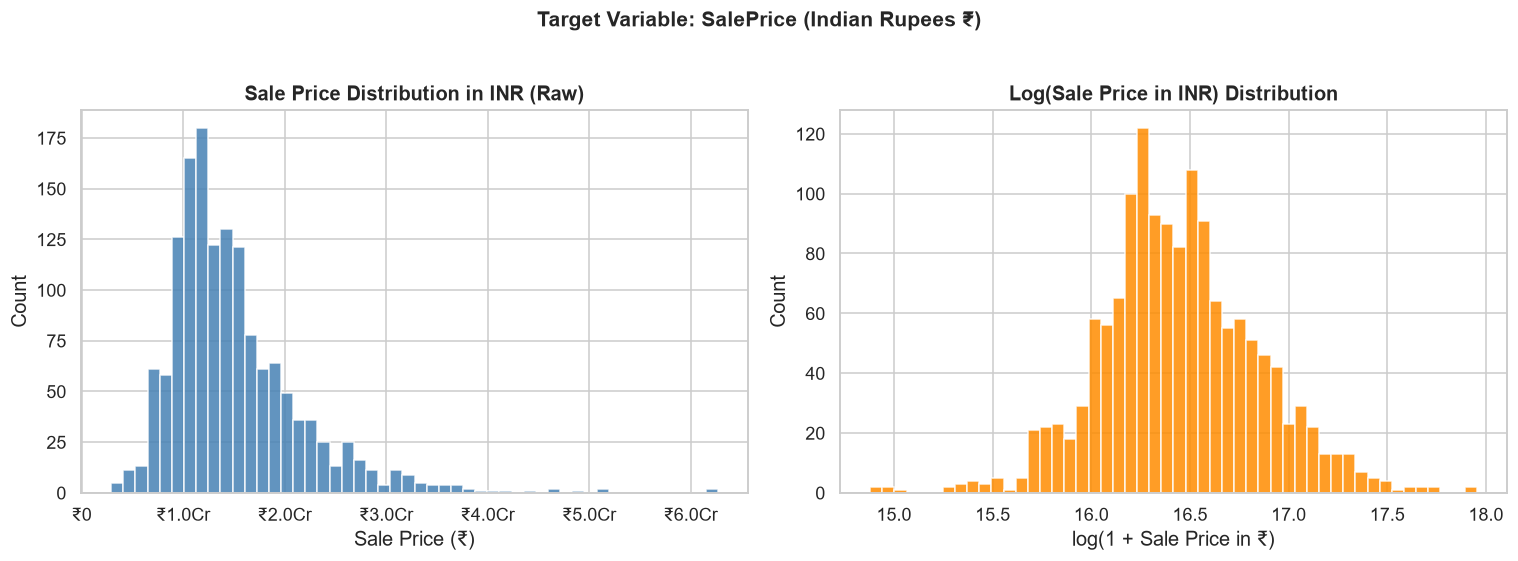

Mean   : ₹15,016,459 (₹1.50 Cr)
Median : ₹13,529,000 (₹1.35 Cr)
Skew   : 1.883  (> 1 = significant right skew)


In [14]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_raw[TARGET].dropna(), bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Sale Price Distribution in INR (Raw)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sale Price (₹)')
axes[0].set_ylabel('Count')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))

log_price = np.log1p(df_raw[TARGET].dropna())
axes[1].hist(log_price, bins=50, color='darkorange', edgecolor='white', alpha=0.85)
axes[1].set_title('Log(Sale Price in INR) Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(1 + Sale Price in ₹)')
axes[1].set_ylabel('Count')

plt.suptitle('Target Variable: SalePrice (Indian Rupees ₹)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Mean   : ₹{df_raw[TARGET].mean():,.0f} ({format_inr(df_raw[TARGET].mean())})')
print(f'Median : ₹{df_raw[TARGET].median():,.0f} ({format_inr(df_raw[TARGET].median())})')
print(f'Skew   : {df_raw[TARGET].skew():.3f}  (> 1 = significant right skew)')


Columns with missing values: 19



,Missing Count,Missing Pct
PoolQC,1453,99.520000
MiscFeature,1406,96.300000
Alley,1369,93.770000
Fence,1179,80.750000
FireplaceQu,690,47.260000
LotFrontage,259,17.740000
GarageCond,81,5.550000
GarageType,81,5.550000
GarageYrBlt,81,5.550000
GarageFinish,81,5.550000


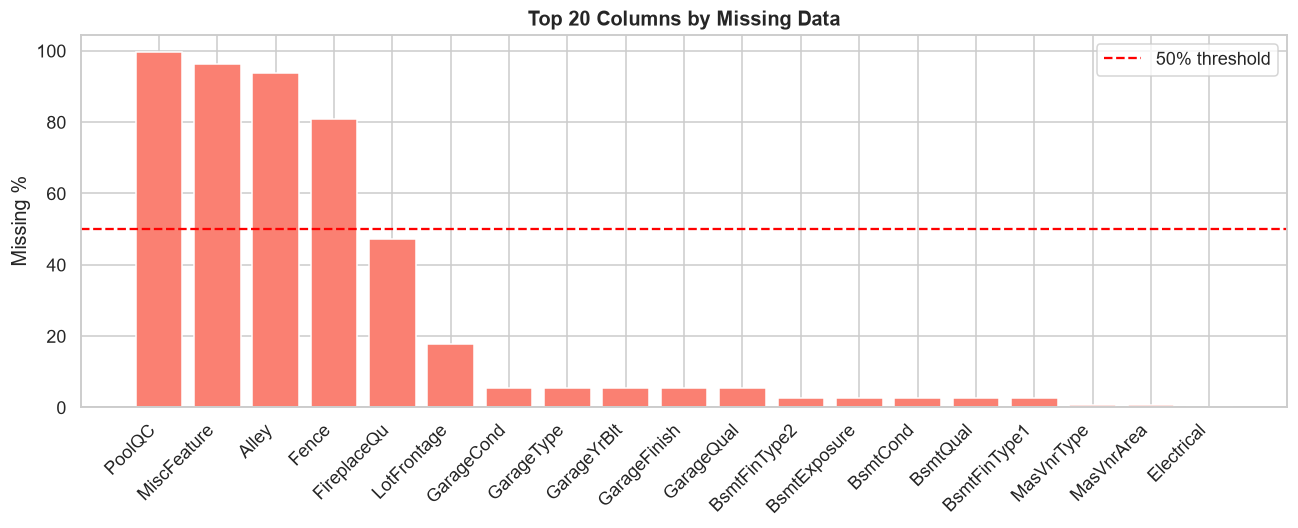

In [15]:
# Missing values analysis
missing = df_raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing Pct': missing_pct
})

print(f'Columns with missing values: {len(missing_df)}')
print()
display(missing_df.style.background_gradient(subset=['Missing Pct'], cmap='Reds'))

# Bar chart
plt.figure(figsize=(12, 5))
top_missing = missing_df.head(20)
plt.bar(top_missing.index, top_missing['Missing Pct'], color='salmon', edgecolor='white')
plt.xticks(rotation=45, ha='right')
plt.title('Top 20 Columns by Missing Data', fontsize=13, fontweight='bold')
plt.ylabel('Missing %')
plt.axhline(50, color='red', linestyle='--', linewidth=1.5, label='50% threshold')
plt.legend()
plt.tight_layout()
plt.show()

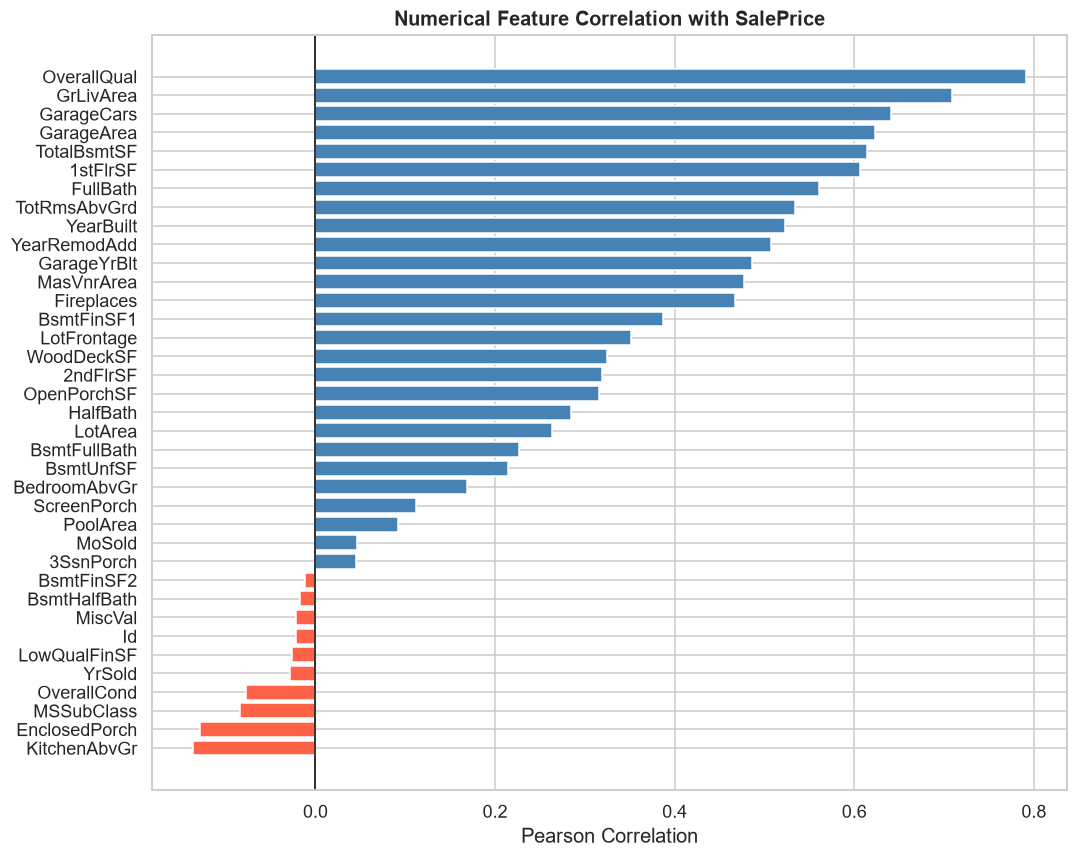

In [16]:
# Correlation of numerical features with SalePrice
numeric_df = df_raw[num_cols + [TARGET]].copy()
corr_with_target = (
    numeric_df.corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 8))
colors = ['steelblue' if v > 0 else 'tomato' for v in corr_with_target]
plt.barh(corr_with_target.index, corr_with_target.values, color=colors, edgecolor='white')
plt.axvline(0, color='black', linewidth=1)
plt.title('Numerical Feature Correlation with SalePrice', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

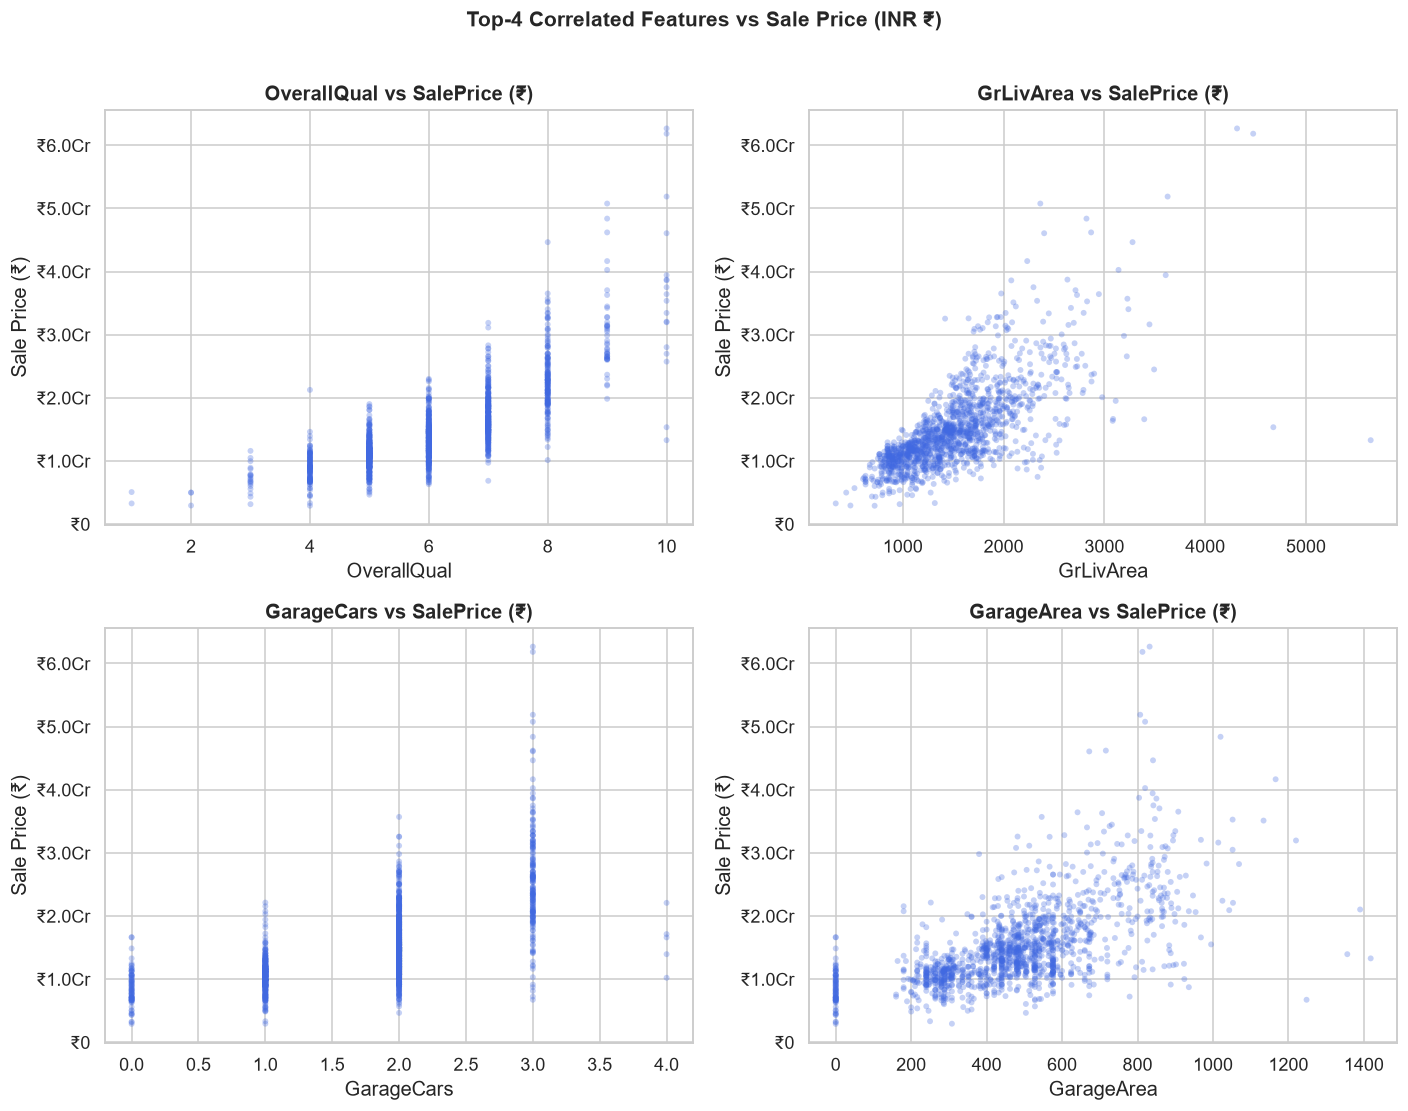

In [17]:
# Key feature scatter plots (top 4 correlated numerical features)
top_features = corr_with_target.head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, feat in zip(axes.flat, top_features):
    ax.scatter(df_raw[feat], df_raw[TARGET], alpha=0.3, s=15, color='royalblue', edgecolors='none')
    ax.set_xlabel(feat)
    ax.set_ylabel('Sale Price (₹)')
    ax.set_title(f'{feat} vs SalePrice (₹)', fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))

plt.suptitle('Top-4 Correlated Features vs Sale Price (INR ₹)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


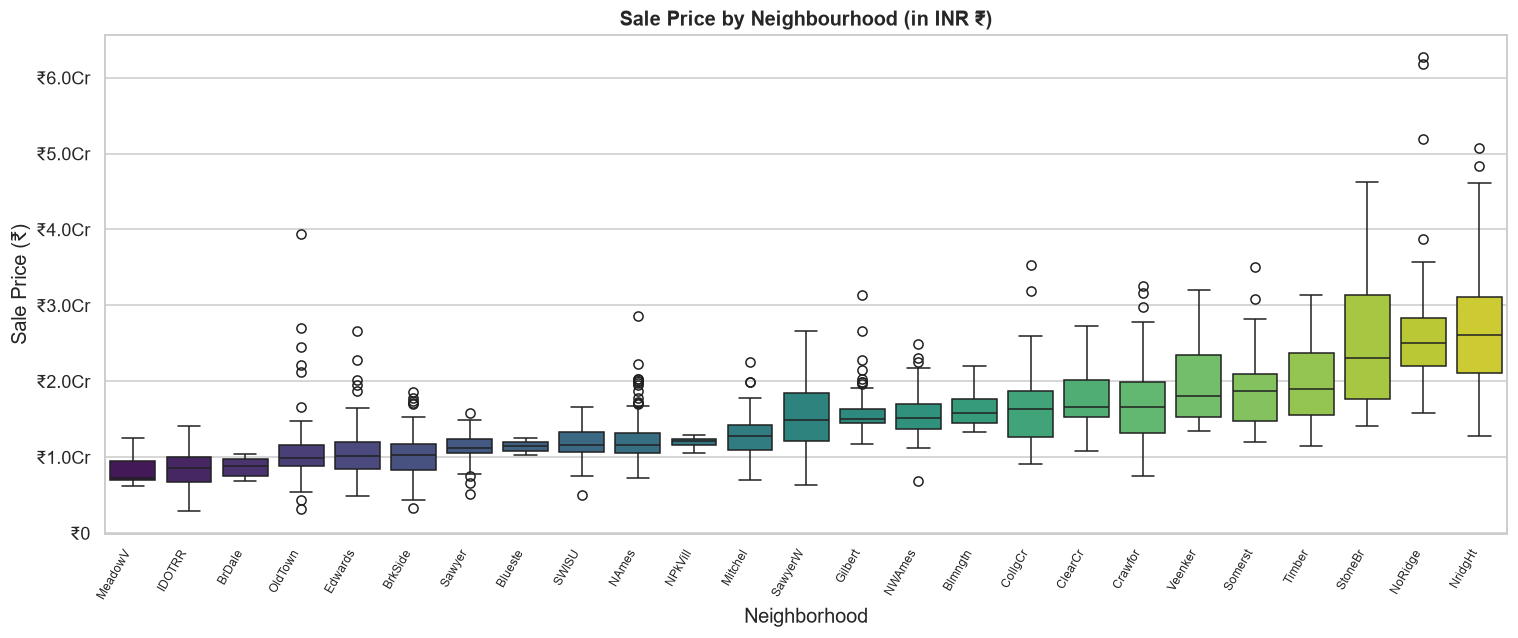

In [18]:
# Neighbourhood vs SalePrice
if 'Neighborhood' in df_raw.columns:
    nbhd_order = (
        df_raw.groupby('Neighborhood')[TARGET].median()
        .sort_values().index
    )
    plt.figure(figsize=(14, 6))
    sns.boxplot(data=df_raw, x='Neighborhood', y=TARGET,
                order=nbhd_order, palette='viridis')
    plt.xticks(rotation=60, ha='right', fontsize=8)
    plt.title('Sale Price by Neighbourhood (in INR ₹)', fontsize=13, fontweight='bold')
    plt.ylabel('Sale Price (₹)')
    plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))
    plt.tight_layout()
    plt.show()


---
## Section 4 - Data Cleaning

### Strategy

| Problem | Approach |
|---|---|
| Columns > 80% missing | Drop entirely |
| Rows with missing target | Drop rows |
| Numerical outliers | IQR-based removal (factor = 3.0) |
| Remaining missing values | Handled inside the Pipeline (no data leakage) |
| Categorical encoding | OneHotEncoder (nominal) + OrdinalEncoder (ordinal) inside Pipeline |

> **Key principle**: All imputation and encoding happen *inside* the scikit-learn Pipeline fitted on training data only.

In [19]:
# Step 1: Drop rows where target is missing
df = df_raw.dropna(subset=[TARGET]).copy()
print(f'After dropping missing target rows: {df.shape}')

# Step 2: Drop columns with > 80% missing
MISS_THRESHOLD = 0.80
miss_frac = df.isnull().mean()
cols_to_drop = miss_frac[miss_frac > MISS_THRESHOLD].index.tolist()

# Also drop Id column if present
if 'Id' in df.columns:
    cols_to_drop.append('Id')

df.drop(columns=cols_to_drop, inplace=True)
print(f'Dropped {len(cols_to_drop)} columns (>80% missing or ID): {cols_to_drop}')
print(f'Shape after column drop: {df.shape}')

After dropping missing target rows: (1460, 81)
Dropped 5 columns (>80% missing or ID): ['Alley', 'PoolQC', 'Fence', 'MiscFeature', 'Id']
Shape after column drop: (1460, 76)


In [20]:
# Step 3: Outlier detection and removal using IQR method
def remove_iqr_outliers(dataframe, column, factor=3.0):
    """
    Remove rows where column falls outside [Q1 - factor*IQR, Q3 + factor*IQR].
    factor=3.0 is conservative -- only removes extreme outliers.
    """
    Q1  = dataframe[column].quantile(0.25)
    Q3  = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    before = len(dataframe)
    dataframe = dataframe[
        (dataframe[column] >= lower) & (dataframe[column] <= upper)
    ]
    removed = before - len(dataframe)
    if column == TARGET:
        print(f'  [{column}]  bounds=[₹{lower:,.0f}, ₹{upper:,.0f}] ({format_inr(lower)} to {format_inr(upper)})  removed {removed} rows')
    else:
        print(f'  [{column}]  bounds=[{lower:,.0f}, {upper:,.0f}]  removed {removed} rows')
    return dataframe


print('Outlier removal (IQR factor = 3.0):')
outlier_cols = [TARGET]
for c in ['GrLivArea', 'TotalBsmtSF', 'LotArea']:
    if c in df.columns:
        outlier_cols.append(c)

for col in outlier_cols:
    df = remove_iqr_outliers(df, col, factor=3.0)

df.reset_index(drop=True, inplace=True)
print(f'\nShape after outlier removal: {df.shape}')


Outlier removal (IQR factor = 3.0):
  [SalePrice]  bounds=[₹-10,134,300, ₹38,684,225] (₹-1.01 Cr to ₹3.87 Cr)  removed 12 rows
  [GrLivArea]  bounds=[-794, 3,690]  removed 2 rows
  [TotalBsmtSF]  bounds=[-665, 2,739]  removed 2 rows
  [LotArea]  bounds=[-4,450, 23,434]  removed 31 rows

Shape after outlier removal: (1413, 76)


In [21]:
# Step 4: Feature / target split + log-transform target
X = df.drop(columns=[TARGET])
y = np.log1p(df[TARGET])    # log-transform reduces right skew

print(f'X shape : {X.shape}')
print(f'y shape : {y.shape}')
print(f'y range : {y.min():.3f} to {y.max():.3f}  (log scale)')

# Step 5: Train / test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print(f'Training set : {X_train.shape[0]} rows')
print(f'Test set     : {X_test.shape[0]} rows')

X shape : (1413, 75)
y shape : (1413,)
y range : 14.879 to 17.469  (log scale)
Training set : 1130 rows
Test set     : 283 rows


---
## Section 5 - Building the ColumnTransformer Pipeline

### Why use a Pipeline?

A Pipeline chains preprocessing steps and the model into a single object. This guarantees:
1. **No data leakage** -- imputers/encoders are always fitted on training data only
2. **Portability** -- save one .pkl file that includes all preprocessing
3. **Reproducibility** -- predict() automatically applies the same transformations

### Column groups for ColumnTransformer

| Group | Transformer chain | Reasoning |
|---|---|---|
| Numerical | SimpleImputer(median) + StandardScaler | Median is robust to outliers |
| Ordinal categorical | SimpleImputer(constant='NA') + OrdinalEncoder | Preserves natural quality ordering |
| Nominal categorical | SimpleImputer(most_frequent) + OneHotEncoder | Binary dummy columns for unordered labels |

In [22]:
# Identify feature groups from TRAINING set only
num_features = X_train.select_dtypes(include=['number']).columns.tolist()

# Columns with a natural ordering (quality / condition scales)
ordinal_candidates = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
    'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual',
    'GarageCond', 'PoolQC', 'Fence',
]
ordinal_features = [c for c in ordinal_candidates if c in X_train.columns]
all_cat = X_train.select_dtypes(exclude=['number']).columns.tolist()
nominal_features = [c for c in all_cat if c not in ordinal_features]

print(f'Numerical features  : {len(num_features)}')
print(f'Ordinal features    : {len(ordinal_features)}  {ordinal_features}')
print(f'Nominal features    : {len(nominal_features)}')

Numerical features  : 36
Ordinal features    : 9  ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']
Nominal features    : 30


In [23]:
# Ordinal category order definitions
# The quality/condition columns use: NA < Po < Fa < TA < Gd < Ex
QUALITY_ORDER = ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
FENCE_ORDER   = ['NA', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv']

ordinal_categories = []
for col in ordinal_features:
    if col == 'Fence':
        ordinal_categories.append(FENCE_ORDER)
    else:
        ordinal_categories.append(QUALITY_ORDER)

# Numerical pipeline: impute -> scale
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

# Ordinal pipeline: impute with 'NA' -> encode with known order
ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='NA')),
    ('encoder', OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1,
    )),
])

# Nominal pipeline: impute with most_frequent -> one-hot encode
nominal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False,
    )),
])

# ColumnTransformer combines all three sub-pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num',     numerical_pipeline, num_features),
        ('ordinal', ordinal_pipeline,   ordinal_features),
        ('nominal', nominal_pipeline,   nominal_features),
    ],
    remainder='drop',
)

print('ColumnTransformer built!')
print(f'  Numerical  : {len(num_features)} features')
print(f'  Ordinal    : {len(ordinal_features)} features')
print(f'  Nominal    : {len(nominal_features)} features (will expand via OHE)')

ColumnTransformer built!
  Numerical  : 36 features
  Ordinal    : 9 features
  Nominal    : 30 features (will expand via OHE)


In [24]:
# Sanity check -- fit & transform training set
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed  = preprocessor.transform(X_test)

print(f'X_train shape BEFORE transform : {X_train.shape}')
print(f'X_train shape AFTER  transform : {X_train_transformed.shape}')
print(f'X_test  shape AFTER  transform : {X_test_transformed.shape}')
print()
print('OHE expanded the nominal features into many binary columns.')
print('All NaN values have been imputed -- no missing data remains.')

X_train shape BEFORE transform : (1130, 75)
X_train shape AFTER  transform : (1130, 238)
X_test  shape AFTER  transform : (283, 238)

OHE expanded the nominal features into many binary columns.
All NaN values have been imputed -- no missing data remains.


---
## Section 6 - Train Models Inside End-to-End Pipelines

Each model is wrapped in Pipeline(preprocessor + model). This means:
- `pipeline.fit(X_train, y_train)` -- preprocesses then trains on training data only
- `pipeline.predict(X_test)` -- applies same preprocessing then predicts

**Zero risk of data leakage** because fit() is only called on training data.

In [25]:
# Helper: evaluate a Pipeline
def evaluate_pipeline(name, estimator, X_tr, y_tr, X_te, y_te):
    """
    Fit the pipeline on training data and evaluate on the test set.
    Metrics are in the original price scale (inverse log1p) in Indian Rupees (₹).
    """
    estimator.fit(X_tr, y_tr)
    y_pred_log = estimator.predict(X_te)

    # Inverse log1p to get back to Indian Rupee (INR ₹) scale
    y_pred = np.expm1(y_pred_log)
    y_true = np.expm1(y_te)

    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)

    return {
        'Model' : name,
        'MAE'   : mae,
        'MSE'   : mse,
        'RMSE'  : rmse,
        'R2'    : r2,
    }, estimator, y_pred


# Define model pipelines
pipelines = {
    'Linear Regression' : Pipeline([('prep', preprocessor), ('model', LinearRegression())]),
    'Ridge Regression'  : Pipeline([('prep', preprocessor), ('model', Ridge(alpha=10.0, random_state=SEED))]),
    'Lasso Regression'  : Pipeline([('prep', preprocessor), ('model', Lasso(alpha=0.001, random_state=SEED, max_iter=10_000))]),
    'Random Forest'     : Pipeline([('prep', preprocessor), ('model', RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1))]),
    'Gradient Boosting' : Pipeline([('prep', preprocessor), ('model', GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED))]),
}

# Train and evaluate all models
results       = []
fitted_pipes  = {}
predictions   = {}

for name, pipe in pipelines.items():
    metrics, fitted, y_pred = evaluate_pipeline(name, pipe, X_train, y_train, X_test, y_test)
    results.append(metrics)
    fitted_pipes[name] = fitted
    predictions[name]  = y_pred
    print(f'  {name:22s} | R2={metrics["R2"]:.4f} | RMSE=₹{metrics["RMSE"]:,.0f} ({format_inr(metrics["RMSE"])}) | MAE=₹{metrics["MAE"]:,.0f} ({format_inr(metrics["MAE"])})')

print('\nAll models trained!')


  Linear Regression      | R2=0.9067 | RMSE=₹1,733,578 (₹17.34 Lakhs) | MAE=₹1,225,860 (₹12.26 Lakhs)
  Ridge Regression       | R2=0.9226 | RMSE=₹1,578,585 (₹15.79 Lakhs) | MAE=₹1,148,477 (₹11.48 Lakhs)
  Lasso Regression       | R2=0.9229 | RMSE=₹1,575,639 (₹15.76 Lakhs) | MAE=₹1,114,853 (₹11.15 Lakhs)
  Random Forest          | R2=0.8864 | RMSE=₹1,912,691 (₹19.13 Lakhs) | MAE=₹1,279,107 (₹12.79 Lakhs)
  Gradient Boosting      | R2=0.9126 | RMSE=₹1,677,925 (₹16.78 Lakhs) | MAE=₹1,182,992 (₹11.83 Lakhs)

All models trained!


---
## Section 7 - Model Comparison

In [26]:
# Results table
results_df = pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)

display(
    results_df.style
    .format({'MAE': '₹{:,.0f}', 'MSE': '₹{:,.0f}', 'RMSE': '₹{:,.0f}', 'R2': '{:.4f}'})
    .background_gradient(subset=['R2'],   cmap='Greens')
    .background_gradient(subset=['RMSE'], cmap='Reds_r')
    .set_caption('Model Comparison -- Ames Housing Dataset (in Indian Rupees ₹)')
)


,Model,MAE,MSE,RMSE,R2
0,Lasso Regression,"₹1,114,853","₹2,482,638,765,573","₹1,575,639",0.9229
1,Ridge Regression,"₹1,148,477","₹2,491,931,120,978","₹1,578,585",0.9226
2,Gradient Boosting,"₹1,182,992","₹2,815,431,880,345","₹1,677,925",0.9126
3,Linear Regression,"₹1,225,860","₹3,005,293,136,455","₹1,733,578",0.9067
4,Random Forest,"₹1,279,107","₹3,658,386,671,982","₹1,912,691",0.8864


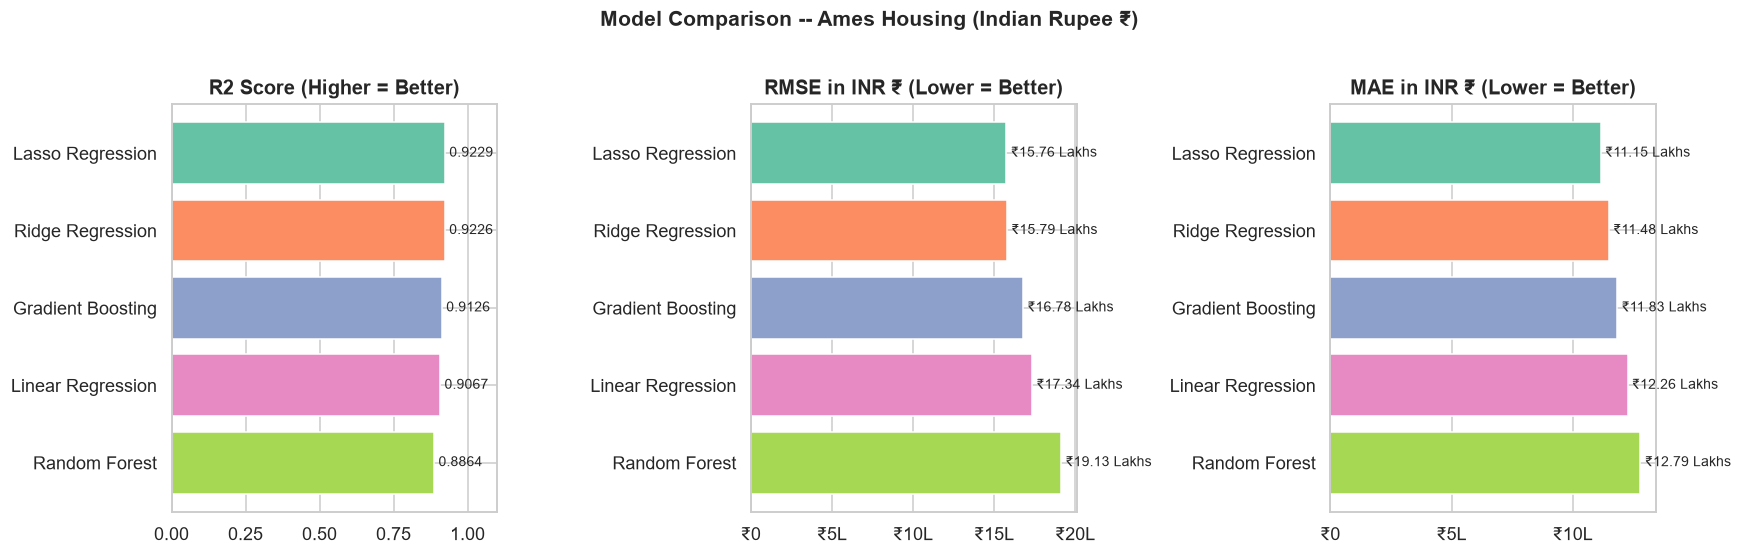

In [27]:
# Comparison bar charts
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model Comparison -- Ames Housing (Indian Rupee ₹)', fontsize=14, fontweight='bold', y=1.01)

colors = sns.color_palette('Set2', len(results_df))
model_names = results_df['Model']

# R2
bars = axes[0].barh(model_names, results_df['R2'], color=colors)
axes[0].set_title('R2 Score (Higher = Better)', fontweight='bold')
axes[0].bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
axes[0].set_xlim(0, 1.1)

# RMSE
bars = axes[1].barh(model_names, results_df['RMSE'], color=colors)
axes[1].set_title('RMSE in INR ₹ (Lower = Better)', fontweight='bold')
axes[1].bar_label(bars, labels=[format_inr(v) for v in results_df['RMSE']], padding=3, fontsize=9)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))

# MAE
bars = axes[2].barh(model_names, results_df['MAE'], color=colors)
axes[2].set_title('MAE in INR ₹ (Lower = Better)', fontweight='bold')
axes[2].bar_label(bars, labels=[format_inr(v) for v in results_df['MAE']], padding=3, fontsize=9)
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))

for ax in axes:
    ax.invert_yaxis()

plt.tight_layout()
plt.show()


---
## Section 8 - Residual Analysis

Residuals are the differences between actual and predicted values. For a well-calibrated model:
- Residuals should be randomly scattered around zero
- There should be no pattern (heteroscedasticity)
- The distribution should be approximately normal

Best model: Lasso Regression  (R2=0.9229)


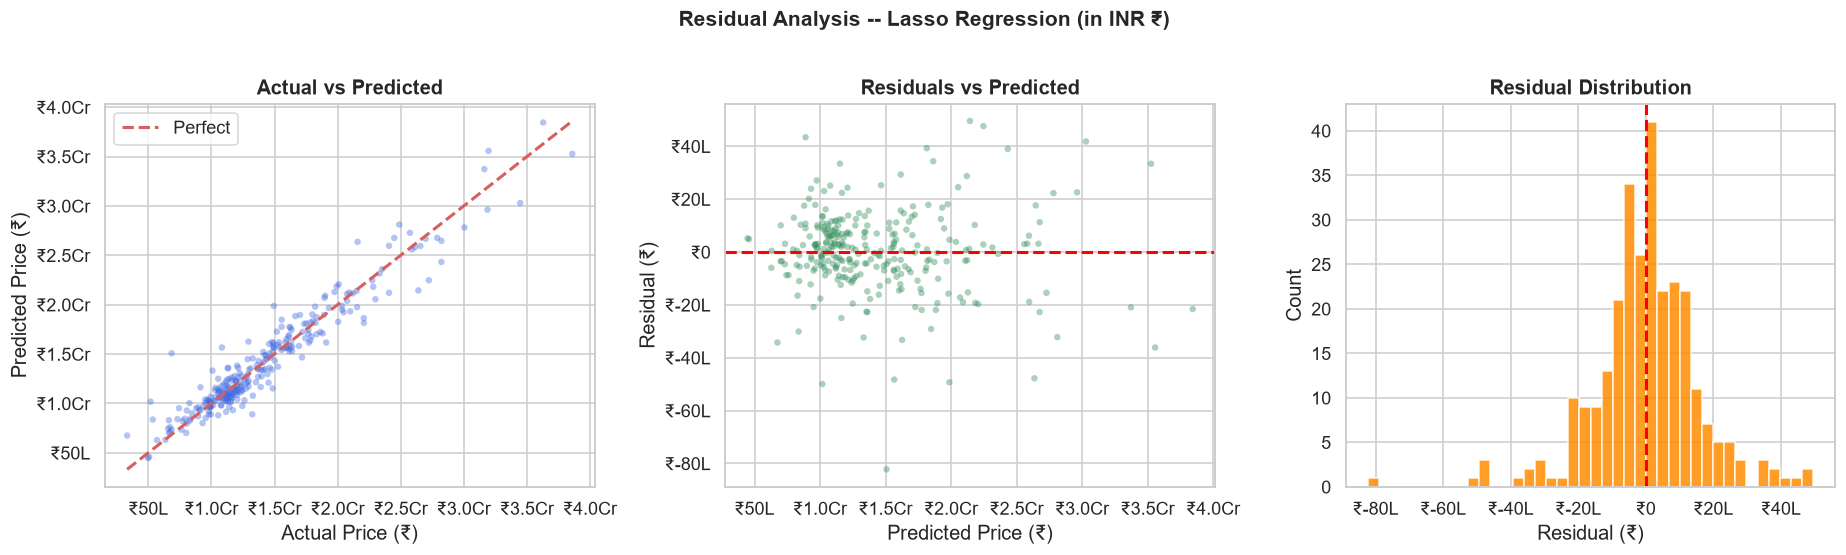

Mean residual : ₹7,783.96 (₹7,784)  (should be close to 0)
Std  residual : ₹1,575,619.93 (₹15.76 Lakhs)


In [28]:
# Select best model for residual analysis
best_name       = results_df.iloc[0]['Model']
best_pipe       = fitted_pipes[best_name]
y_pred_best     = predictions[best_name]
y_true_best     = np.expm1(y_test)
residuals       = y_true_best.values - y_pred_best

print(f'Best model: {best_name}  (R2={results_df.iloc[0]["R2"]:.4f})')

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle(f'Residual Analysis -- {best_name} (in INR ₹)', fontsize=14, fontweight='bold', y=1.01)

# 1. Actual vs Predicted
axes[0].scatter(y_true_best, y_pred_best, alpha=0.4, s=18, color='royalblue', edgecolors='none')
min_v, max_v = y_true_best.min(), y_true_best.max()
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=2, label='Perfect')
axes[0].set_xlabel('Actual Price (₹)')
axes[0].set_ylabel('Predicted Price (₹)')
axes[0].set_title('Actual vs Predicted', fontweight='bold')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))

# 2. Residuals vs Predicted
axes[1].scatter(y_pred_best, residuals, alpha=0.4, s=18, color='seagreen', edgecolors='none')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Predicted Price (₹)')
axes[1].set_ylabel('Residual (₹)')
axes[1].set_title('Residuals vs Predicted', fontweight='bold')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))

# 3. Residual distribution
axes[2].hist(residuals, bins=40, color='darkorange', edgecolor='white', alpha=0.85)
axes[2].axvline(0, color='red', linestyle='--', linewidth=2)
axes[2].set_xlabel('Residual (₹)')
axes[2].set_ylabel('Count')
axes[2].set_title('Residual Distribution', fontweight='bold')
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(inr_tick_formatter))

plt.tight_layout()
plt.show()

print(f'Mean residual : ₹{residuals.mean():,.2f} ({format_inr(residuals.mean())})  (should be close to 0)')
print(f'Std  residual : ₹{residuals.std():,.2f} ({format_inr(residuals.std())})')


---
## Section 9 - Feature Importance

After training inside a Pipeline, we extract feature names from the ColumnTransformer, then read importances from the model step.

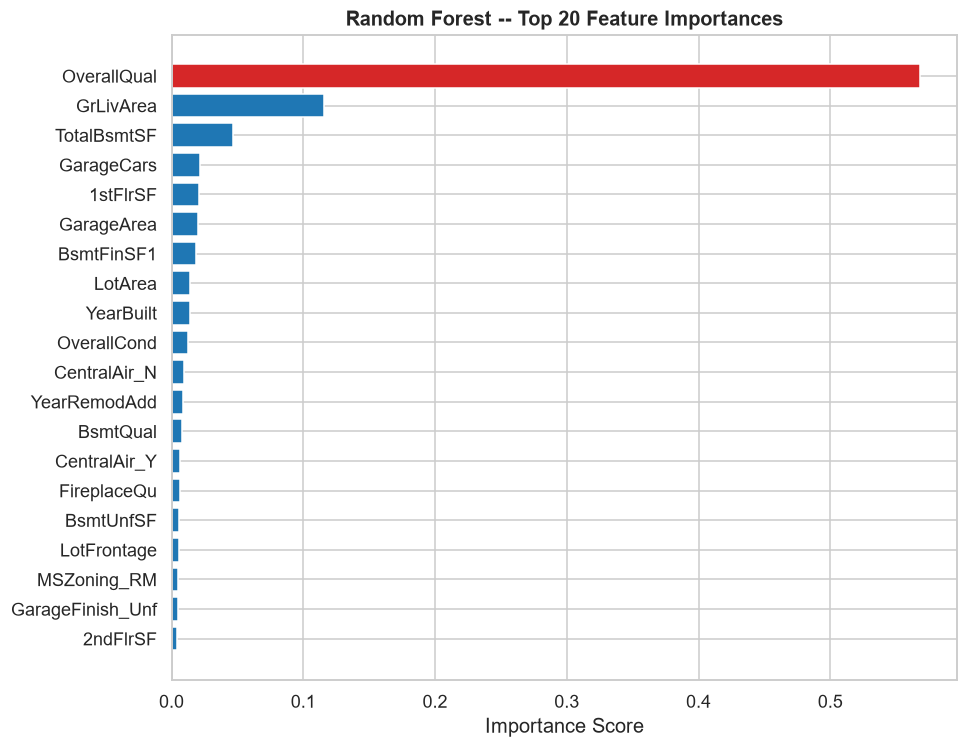

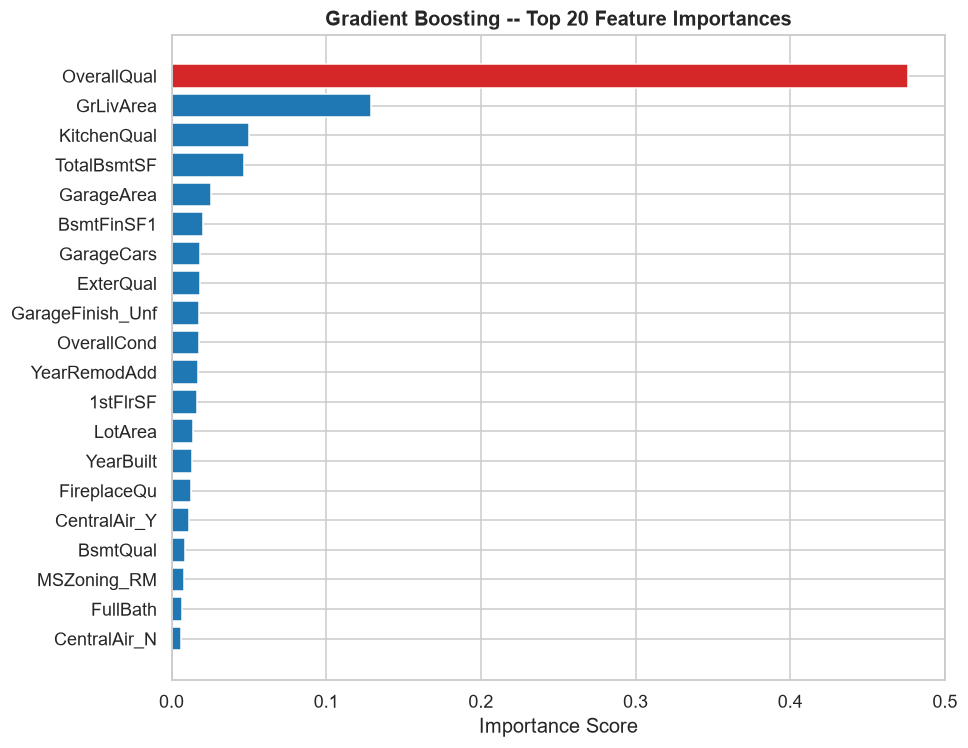

In [29]:
# Helper: extract feature names from a fitted ColumnTransformer
def get_feature_names(col_transformer):
    feature_names = []
    for name, transformer, columns in col_transformer.transformers_:
        if name == 'remainder':
            continue
        if hasattr(transformer, 'named_steps'):
            last_step = list(transformer.named_steps.values())[-1]
            if hasattr(last_step, 'get_feature_names_out'):
                names = last_step.get_feature_names_out(columns)
            else:
                names = columns
        elif hasattr(transformer, 'get_feature_names_out'):
            names = transformer.get_feature_names_out(columns)
        else:
            names = columns
        feature_names.extend(list(names))
    return feature_names


# Feature importances for tree-based models
for mname in ['Random Forest', 'Gradient Boosting']:
    if mname not in fitted_pipes:
        continue
    pipe       = fitted_pipes[mname]
    model_step = pipe.named_steps['model']
    prep_step  = pipe.named_steps['prep']

    feat_names  = get_feature_names(prep_step)
    importances = model_step.feature_importances_

    imp_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances})
    imp_df = imp_df.sort_values('Importance', ascending=False).head(20).sort_values('Importance')

    plt.figure(figsize=(9, 7))
    clrs = ['#d62728' if v == imp_df['Importance'].max() else '#1f77b4' for v in imp_df['Importance']]
    plt.barh(imp_df['Feature'], imp_df['Importance'], color=clrs, edgecolor='white')
    plt.title(f'{mname} -- Top 20 Feature Importances', fontsize=13, fontweight='bold')
    plt.xlabel('Importance Score')
    plt.tight_layout()
    plt.show()

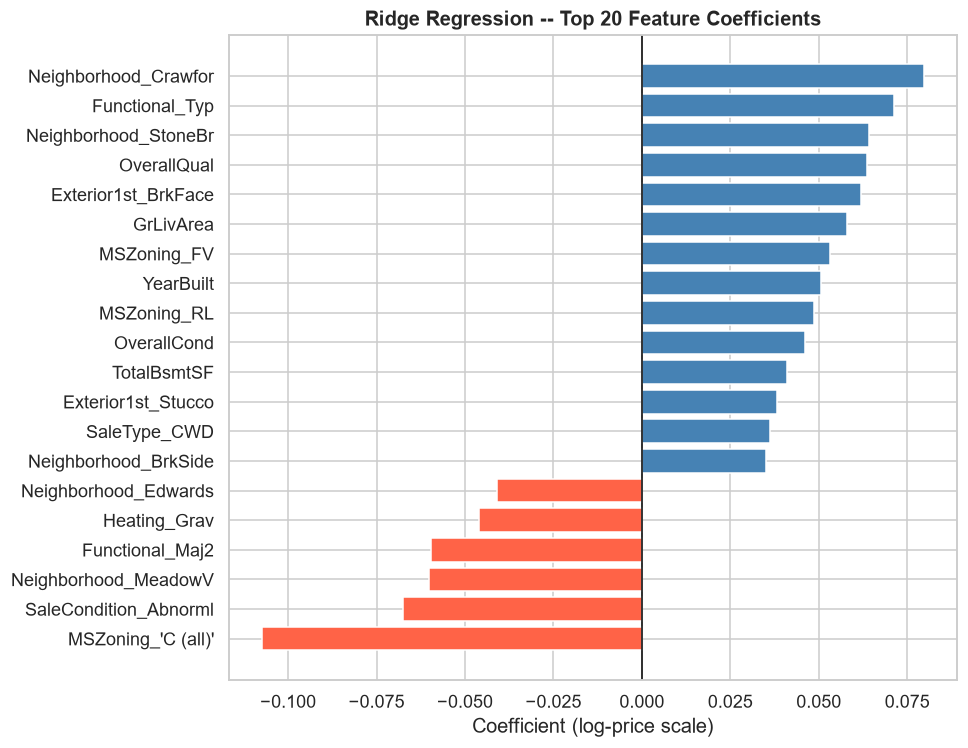

In [30]:
# Ridge coefficients (top features)
if 'Ridge Regression' in fitted_pipes:
    ridge_pipe  = fitted_pipes['Ridge Regression']
    ridge_model = ridge_pipe.named_steps['model']
    ridge_prep  = ridge_pipe.named_steps['prep']

    feat_names = get_feature_names(ridge_prep)
    coef_df = pd.DataFrame({
        'Feature'    : feat_names,
        'Coefficient': ridge_model.coef_
    })
    coef_df['AbsCoef'] = coef_df['Coefficient'].abs()
    top_coef = coef_df.sort_values('AbsCoef', ascending=False).head(20).sort_values('Coefficient')

    plt.figure(figsize=(9, 7))
    clrs = ['tomato' if c < 0 else 'steelblue' for c in top_coef['Coefficient']]
    plt.barh(top_coef['Feature'], top_coef['Coefficient'], color=clrs, edgecolor='white')
    plt.axvline(0, color='black', linewidth=1)
    plt.title('Ridge Regression -- Top 20 Feature Coefficients', fontsize=13, fontweight='bold')
    plt.xlabel('Coefficient (log-price scale)')
    plt.tight_layout()
    plt.show()

---
## Section 10 - Cross-Validation

**k-fold cross-validation** evaluates the model on k different holdout sets and averages the scores for a more reliable estimate of generalisation performance.

In [31]:
# 5-fold cross-validation on the top models
cv_results = {}

cv_models = {
    'Random Forest'     : Pipeline([('prep', preprocessor), ('model', RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1))]),
    'Gradient Boosting' : Pipeline([('prep', preprocessor), ('model', GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=SEED))]),
    'Ridge Regression'  : Pipeline([('prep', preprocessor), ('model', Ridge(alpha=10.0, random_state=SEED))]),
}

print('5-fold Cross-Validation (scoring: R2):')
for mname, pipe in cv_models.items():
    scores = cross_val_score(pipe, X, y, cv=5, scoring='r2', n_jobs=-1)
    cv_results[mname] = scores
    print(f'  {mname:22s} | mean={scores.mean():.4f}  std={scores.std():.4f}  folds={scores.round(4)}')

5-fold Cross-Validation (scoring: R2):
  Random Forest          | mean=0.8765  std=0.0095  folds=[0.8728 0.8933 0.8678 0.8803 0.8684]
  Gradient Boosting      | mean=0.9049  std=0.0092  folds=[0.9153 0.9067 0.8886 0.9115 0.9026]
  Ridge Regression       | mean=0.9144  std=0.0051  folds=[0.9184 0.919  0.9075 0.9182 0.9088]


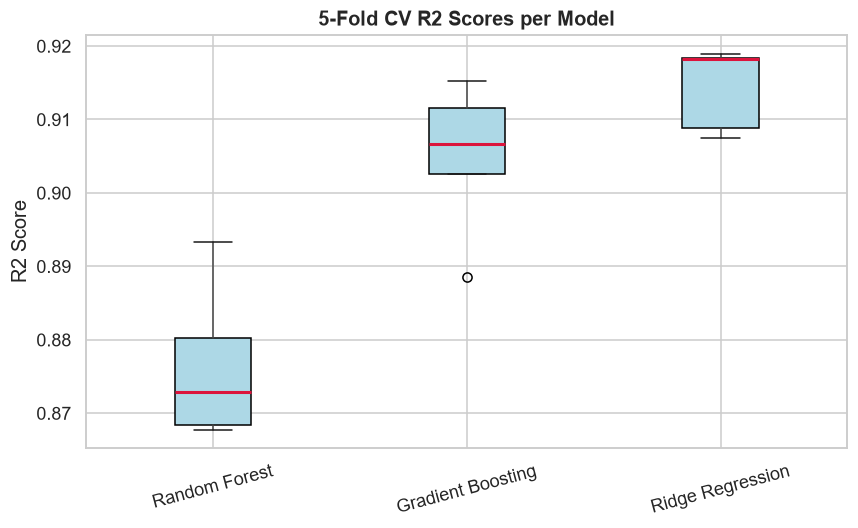

In [32]:
# CV score box plot
plt.figure(figsize=(8, 5))
cv_df = pd.DataFrame(cv_results)
cv_df.boxplot(column=list(cv_results.keys()), patch_artist=True,
              boxprops=dict(facecolor='lightblue'),
              medianprops=dict(color='crimson', linewidth=2))
plt.title('5-Fold CV R2 Scores per Model', fontsize=13, fontweight='bold')
plt.ylabel('R2 Score')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

---
## Section 11 - Sample Prediction

We predict the sale price of a new house using the best end-to-end pipeline.
The input is **raw** -- no manual preprocessing required; the pipeline handles everything.

In [33]:
# Build a sample house with median/mode values for all features
sample_row = {}
for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        try:
            sample_row[col] = float(X[col].median())
        except Exception:
            vals = X[col].dropna()
            sample_row[col] = float(vals.iloc[0]) if len(vals) > 0 else 0.0
    else:
        vals = X[col].dropna()
        sample_row[col] = str(vals.mode()[0]) if len(vals) > 0 else 'None'

# Override with specific house characteristics
overrides = {
    'GrLivArea'    : 1800,
    'BedroomAbvGr' : 3,
    'FullBath'     : 2,
    'YearBuilt'    : 2005,
    'OverallQual'  : 7,
    'GarageCars'   : 2,
    'TotalBsmtSF'  : 900,
}
for k, v in overrides.items():
    if k in sample_row:
        sample_row[k] = v

sample_df = pd.DataFrame([sample_row])

# Predict
log_pred   = best_pipe.predict(sample_df)[0]
price_pred = np.expm1(log_pred)

print('=' * 55)
print('  SAMPLE PREDICTION (in Indian Rupees)')
print('=' * 55)
print(f'  Model         : {best_name}')
for k, v in overrides.items():
    print(f'  {k:<15}: {v}')
print('-' * 55)
print(f'  Predicted Sale Price : ₹{price_pred:,.2f} ({format_inr(price_pred)})')
print('=' * 55)


  SAMPLE PREDICTION (in Indian Rupees)
  Model         : Lasso Regression
  GrLivArea      : 1800
  BedroomAbvGr   : 3
  FullBath       : 2
  YearBuilt      : 2005
  OverallQual    : 7
  GarageCars     : 2
  TotalBsmtSF    : 900
-------------------------------------------------------
  Predicted Sale Price : ₹16,314,523.08 (₹1.63 Cr)


---
## Section 12 - Save the Full Pipeline

The Pipeline bundles preprocessing + model into one object.
Saving a single .pkl file is enough -- no separate scaler needed.

In [34]:
# Save the complete pipeline
MODEL_PATH = 'ames_house_price_pipeline.pkl'
joblib.dump(best_pipe, MODEL_PATH)
print(f'Pipeline saved : {MODEL_PATH}')
print(f'Model type     : {best_name}')
print(f'Target currency: Indian Rupee (INR / ₹)')
print(f'File includes  : ColumnTransformer (imputer + encoder + scaler) + {best_name}')


Pipeline saved : ames_house_price_pipeline.pkl
Model type     : Lasso Regression
Target currency: Indian Rupee (INR / ₹)
File includes  : ColumnTransformer (imputer + encoder + scaler) + Lasso Regression


---
## Section 13 - Load and Test the Saved Pipeline

In [35]:
# Load pipeline
loaded_pipeline = joblib.load('ames_house_price_pipeline.pkl')
print(f'Pipeline loaded! Type: {type(loaded_pipeline).__name__}')

# Predict with loaded pipeline on same sample
log_p = loaded_pipeline.predict(sample_df)[0]
price = np.expm1(log_p)

print(f'Predicted Sale Price (loaded pipeline): ₹{price:,.2f} ({format_inr(price)})')
print('Pipeline loads and predicts correctly on raw input in Indian Rupees!')


Pipeline loaded! Type: Pipeline
Predicted Sale Price (loaded pipeline): ₹16,314,523.08 (₹1.63 Cr)
Pipeline loads and predicts correctly on raw input in Indian Rupees!


---
## Section 14 - What We Learned

### Pipeline Architecture

```
Raw DataFrame (79 mixed features, some NaN)
        |
        v
ColumnTransformer
  |-- Numerical  --> SimpleImputer(median) --> StandardScaler
  |-- Ordinal    --> SimpleImputer(constant='NA') --> OrdinalEncoder
  +-- Nominal    --> SimpleImputer(most_frequent) --> OneHotEncoder
        |
        v
  Dense Feature Matrix (hundreds of columns)
        |
        v
  Regression Model (RF / GB / Ridge / ...)
        |
        v
  log(SalePrice in INR)  -->  expm1()  -->  Predicted SalePrice in Indian Rupees (₹)
```

---

### Key lessons

| Concept | What we did |
|---|---|
| **Currency Localisation** | Converted target `SalePrice` to INR (₹) using ₹83 / USD, expressing property values in Lakhs and Crores |
| **Missing value handling** | Dropped columns > 80% missing; imputed the rest inside the pipeline |
| **Outlier handling** | Conservative IQR removal (factor = 3.0) on target and key columns |
| **Target transformation** | log1p(SalePrice) reduced right skew; expm1() inverts for INR readability |
| **Categorical encoding** | OrdinalEncoder for quality scales; OneHotEncoder for nominal labels |
| **Data leakage prevention** | Fit only on X_train; transform X_test separately |
| **Pipelines** | Single .pkl bundles all preprocessing + model into one reusable artefact |
| **Cross-validation** | 5-fold CV gave more reliable R2 estimates than a single split |

---

### Next steps

- **Hyperparameter tuning** with GridSearchCV inside a pipeline
- **Feature engineering** -- TotalSF = GrLivArea + TotalBsmtSF, house age at sale, etc.
- **Target encoding** for high-cardinality categorical columns (e.g., Neighborhood)
- **Stacking / blending** multiple models for improved accuracy
- **FastAPI server integration** for serving INR house price predictions
